# Assignment 09: Gradient Forest and Genomic Turnover

## BIO597 Spatial Analysis of Biodiversity

Repeat the [Lab09](../labs/Lab09-GradientForest.ipynb) workflow for a snake species other than *P. guttatus*. Use SNP genotypes and climate predictors to investigate where modeled genetic turnover occurs along environmental gradients. You may reuse code from the lab.

## Deliverable

Submit this completed notebook with sample maps, SNP diagnostics, predictor importance, turnover curves, an aggregate PCA map/biplot, a single-SNP map/biplot, and short written answers. Save your diagnostic tables, transformed sample coordinates, curves, figures, and a GeoTIFF with one named band per predictor. Use the lab's filtering and model settings; no parameter search, additional algorithm, or future-climate projection is required.


## Install pyGF

Because this notebook environment is a bit wonky you need to redo this install every time you run a new notebook process.

The `pyGF` package is only available in my github repo, so the installation will need to be
'by hand'.

* Open a new terminal and `cd ~` to go to your home directory
* You should already have cloned the pygf repo so you don't need to do this again (but if you need to the command is `git clone https://github.com/isaacovercast/pygf.git`)
* `pip install -e pygf` to install this package and all requirements
* Restart the kernel for this notebook w/ the 'circle arrow' button in the notebook toolbar
* Now you should be able to do the imports in the next cell

## 1. Import packages and set up paths

Run this notebook from `docs/assignments` using the same Python environment as Lab09, with `pygf` and its notebook dependencies installed. The imports and JupyterHub paths are provided below.

The assignment's genetic data are in **`/home/jovyan/shared/EasternSnakeGenetics`**. The climate layers use the same **`/home/jovyan/shared-readwrite/bioclim`** directory as Lab09. Keep all input paths in these two variables so later calls use the same files. Save your results in your own repository, not in a shared input directory.

For local work, the genetic files are in `../labs/EasternSnakes`; you must also point `bioclim_dir` to a local directory containing the 19 regional bioclim rasters. The Maine-only climate layers from earlier labs do not cover these samples.


In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pygf import GradientForest, read_coordinates, read_vcf, sample_environment

genetics_dir = Path("/home/jovyan/shared/EasternSnakeGenetics")
bioclim_dir = Path("/home/jovyan/shared/bioclim")


## 2. Choose another snake species

Choose one of the three species with both a VCF and a headerless coordinate file. Use the **file stem** exactly as shown; do not choose the lab's `Pguttatus`.

| File stem | Species | Genetic files |
| --- | --- | --- |
| `Acontortrix` | *Agkistrodon contortrix* | `Acontortrix.vcf`, `Acontortrix_coords.txt` |
| `Lgetula` | *Lampropeltis getula* | `Lgetula.vcf`, `Lgetula_coords.txt` |
| `Sdekayi` | *Storeria dekayi* | `Sdekayi.vcf`, `Sdekayi_coords.txt` |

The `.txt` coordinate files contain sample ID, longitude, and latitude **without a header**, as expected by `read_coordinates()`. Use these files rather than the similarly named `.csv` tables.


In [2]:
target_species = "Acontortrix"

species_names = {
    "Acontortrix": "Agkistrodon contortrix",
    "Lgetula": "Lampropeltis getula",
    "Sdekayi": "Storeria dekayi",
}
assert target_species in species_names, "Acontortrix"

species_name = species_names[target_species]
vcf_path = genetics_dir / f"{target_species}.vcf"
coords_path = genetics_dir / f"{target_species}_coords.txt"
assert vcf_path.is_file(), f"VCF not found: {vcf_path}"
assert coords_path.is_file(), f"Coordinates not found: {coords_path}"

output_dir = Path("Assignment09_outputs") / target_species
output_dir.mkdir(parents=True, exist_ok=True)
print(species_name)
print(vcf_path)
print(coords_path)


Agkistrodon contortrix
/home/jovyan/shared/EasternSnakeGenetics/Acontortrix.vcf
/home/jovyan/shared/EasternSnakeGenetics/Acontortrix_coords.txt


**Why this species?** Give one biological reason for your choice.

*Your answer:* Eastern copperhead is a snake, prefers warm areas. 

## 3. Read coordinates and filtered genotypes

Read `coords_path` into `sites` with `read_coordinates()`. Read `vcf_path` into `genotypes` with `read_vcf()`, passing `samples=sites` so genotype rows follow coordinate-file order. Keep the lab settings:

- `min_call_rate=0.8`
- `min_maf=0.05`
- `one_per_contig=True`
- `max_variants=256`
- `random_state=42`

Display the number of individuals and retained SNPs. Map the sample locations with a title naming your species. These points describe sampling, not the species' entire range.


Text(0.5, 1.0, 'Agkistrodon contortrix genotypes across sites')

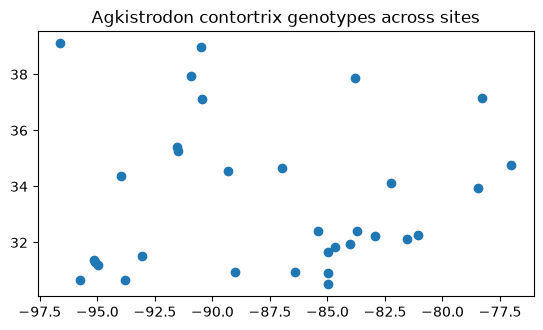

In [43]:
# Read coordinates as sites.
sites = read_coordinates("/home/jovyan/shared/EasternSnakeGenetics/Acontortrix_coords.txt")
# Read the VCF as genotypes, using samples=sites and all five settings above.
genotypes = read_vcf(
    "/home/jovyan/shared/EasternSnakeGenetics/Acontortrix.vcf",
    samples=sites,
    min_call_rate=0.8,
    min_maf=0.05,
    one_per_contig=True,
    max_variants=256,
    random_state=42,
)
# Use genotypes.dosage.to_pandas().shape to inspect individuals × SNPs.
genotypes.dosage.to_pandas().shape
# Print the dimensions and plot sites with a species title.
sites.plot()
plt.title("Agkistrodon contortrix genotypes across sites")




**Interpretation:**

1. What do dosage values 0, 1, and 2 represent? How does a missing call differ from a zero? Zero just means there are zero alternate copies whereas NaN (or missing
The dosage values are the options for what the genotype is. 
2. What do call rate and minor allele frequency filter out? Why might the chosen SNP subset affect your conclusions?
Call rate removes SNPs with too much missing data, removes SNPS where an allele is very rare. The chosen SNP subset may affect conclusion becasue filtering these out may miss real variation or very rare alleles. 
3. Why does taking one SNP per RAD contig reduce repeated local information without guaranteeing independent loci?
Less local repitition, reduces duplicate responses, and cleans up the forest by only contributing one response ratehr than many across a loci. 
*Your answers:*

## 4. Sample climate and align individuals

Extract all 19 climate variables at the sample locations. The provided code removes rows with missing climate and aligns all three inputs to the same IDs. Missing genotypes remain `NaN`; each SNP's forest uses its observed calls. Do not replace missing genotypes with zeros.

`sample_environment()` reprojects points to the raster CRS and samples raster values at those locations. It also remembers the source directory and sampling region for mapping.


In [6]:
n_before = len(sites)
X = sample_environment(bioclim_dir, sites, drop_missing=True)
y = genotypes.dosage.to_pandas().loc[X.index]
sites = sites.loc[X.index].copy()

assert sites.index.equals(X.index)
assert X.index.equals(y.index)
assert np.isfinite(X.to_numpy()).all()
assert X.shape[1] == 19, "Use the full regional bioclim stack."

print("Individuals before climate extraction:", n_before)
print("Individuals with complete climate:", len(X))
print("Climate predictors:", X.shape[1])
print("Filtered SNPs:", y.shape[1])
X.head()


Individuals before climate extraction: 32
Individuals with complete climate: 32
Climate predictors: 19
Filtered SNPs: 256


,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
CAS203553,12.089167,11.342333,29.732447,971.987549,30.827999,-7.320,38.147999,21.476667,-0.535333,23.640667,-0.535333,964.0,103.0,45.0,22.392479,291.0,167.0,272.0,167.0
CAS203555,12.550834,12.756333,33.804150,919.279175,31.136000,-6.600,37.736000,12.374666,0.666000,23.500000,0.666000,1055.0,114.0,54.0,19.611605,313.0,195.0,278.0,195.0
CAS203566,15.568500,12.029667,34.136398,858.739685,33.048000,-2.192,35.240002,15.554667,25.916666,25.916666,4.601333,1284.0,134.0,82.0,19.554363,396.0,266.0,266.0,298.0
CAS203564,13.512000,12.945333,33.813950,920.797546,32.332001,-5.952,38.284000,13.246667,1.638667,24.493334,1.638667,1163.0,124.0,72.0,17.141624,347.0,259.0,284.0,259.0
KU337018,12.463500,12.875667,31.212223,1033.452515,32.652000,-8.600,41.251999,22.460667,-0.764000,24.902000,-0.764000,888.0,134.0,22.0,51.533260,364.0,72.0,322.0,72.0


variant,RAD_4:34:T:C,RAD_62:90:G:A,RAD_451:52:C:T,RAD_647:57:A:G,RAD_800:40:G:A,RAD_830:70:T:C,RAD_981:90:C:A,RAD_1017:14:T:C,RAD_1025:29:A:G,RAD_1058:172:G:A,...,RAD_21274:2:A:G,RAD_21315:23:G:A,RAD_21339:46:A:G,RAD_21579:30:T:A,RAD_22016:45:T:C,RAD_22252:44:A:T,RAD_22297:50:G:A,RAD_22336:24:C:T,RAD_22439:21:G:T,RAD_22554:27:G:A
sample,,,,,,,,,,,,,,,,,,,,,
CAS203553,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0,...,0.0,NaN,2.0,2.0,2.0,NaN,NaN,0.0,0.0,NaN
CAS203555,1.0,0.0,0.0,0.0,NaN,2.0,2.0,NaN,0.0,0.0,...,NaN,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CAS203566,2.0,2.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,NaN,...,NaN,0.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,1.0
CAS203564,NaN,NaN,1.0,NaN,0.0,2.0,1.0,NaN,0.0,0.0,...,0.0,NaN,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
KU337018,1.0,0.0,0.0,0.0,0.0,2.0,2.0,1.0,0.0,0.0,...,0.0,0.0,2.0,2.0,0.0,2.0,0.0,0.0,0.0,0.0


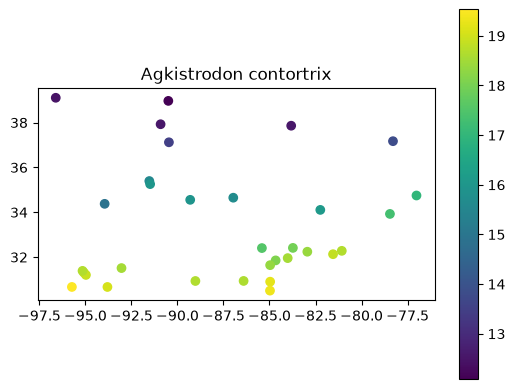

In [10]:
# Map sites colored by X["bio1"] with a legend and species title.
X = sample_environment("/home/jovyan/shared/bioclim", sites)
y = genotypes.dosage.to_pandas()
sites.plot(column=X.bio1, legend=True);
plt.title("Agkistrodon contortrix")

# Inspect y.head() to confirm that SNPs are columns and individuals are rows.
y.head()

**Interpretation:** Were any individuals removed for missing climate? Why must `sites`, `X`, and `y` retain the same IDs and row order? Explain why these responses are individual genotypes rather than population allele frequencies.
No individuals were removed for missing climate. The sites must retain the same IDs and row order becasue this is needed to appropriately associate an indiuals genotype with a climate varaible. These responses are individual genotypes becasue we are using SNP data, which is a direct measure of nucletoide differences in a genome, and is not a summary statistic of a population. 

*Your answer:*

## 5. Fit SNP-specific forests

Create `gf = GradientForest(...)` using `n_estimators=100`, `max_level=2`, `random_state=42`, and `keep_response_curves=True`, then fit it with `X` and `y`.

These settings match the lab. `max_level=2` controls approximate conditional permutations for correlated predictors; it does not limit tree depth. Retaining response curves lets us inspect one SNP later.


In [11]:
# Create gf with the four settings above and fit it to X and y.
gf = GradientForest(
    n_estimators=100, max_level=2, random_state=42, keep_response_curves=True,
).fit(X, y)
# Display gf.response_scores_ sorted by descending oob_r2.
gf.response_scores_.sort_values("oob_r2", ascending=False).head()

,n_observed,oob_r2,oob_coverage,retained,reason
response,,,,,
RAD_22554:27:G:A,26,0.577372,1.0,True,retained
RAD_981:90:C:A,29,0.576139,1.0,True,retained
RAD_12998:69:C:G,27,0.548321,1.0,True,retained
RAD_17496:35:A:G,26,0.500599,1.0,True,retained
RAD_6799:32:G:A,30,0.481125,1.0,True,retained


## 6. Inspect OOB skill and contributing SNPs

Use `gf.response_scores_` to report the number of SNPs evaluated, the number contributing to turnover (`retained=True`), and the fraction contributing. Display the counts of each `reason`, and plot the distribution of `oob_r2` values with a vertical line at zero.

Only SNPs with positive OOB R² and positive permutation importance contribute. Include excluded SNPs in your diagnostic summary, not just the best-scoring ones. If no SNPs contribute, report that outcome and consult the instructor before changing filters or model settings.


SNPs evaluated: 256
SNPs retained: 86
Fractions Contributing: 0.3359375
reason
nonpositive_oob_skill    170
retained                  86
Name: count, dtype: int64


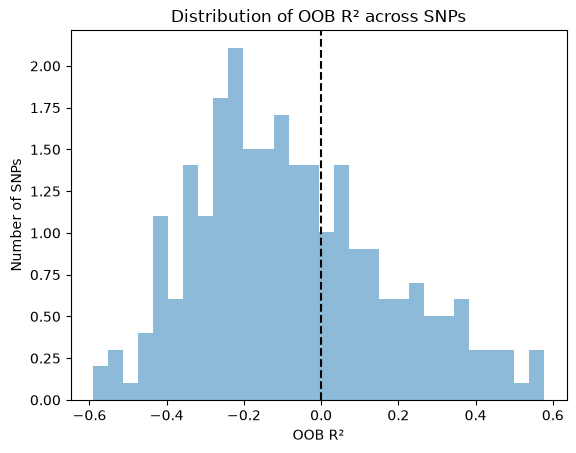

In [26]:
# Store gf.response_scores_ as scores.
scores= gf.response_scores_

# Print evaluated and retained counts and the retained fraction.
evaluated= len(scores)
retained = len(scores[scores["retained"] == True])
fraction= retained/evaluated

print("SNPs evaluated:", evaluated)
print("SNPs retained:", retained)
print("Fractions Contributing:", fraction)

# Display scores["reason"].value_counts().
print(scores["reason"].value_counts())

# Plot scores["oob_r2"].dropna() as a histogram, with a reference line at zero.
plt.hist(scores["oob_r2"].dropna(), bins=30, alpha=0.5, density=True)
plt.axvline(0, color="black", linestyle="--", label="OOB R² = 0")
plt.xlabel("OOB R²")
plt.ylabel("Number of SNPs")
plt.title("Distribution of OOB R² across SNPs")
plt.show()

**Interpretation:** What does an OOB R² below zero mean? Why does a positive OOB score not establish either adaptation or accurate prediction in a new geographic region?
OOB R2 below zero means that those SNPs are not contributing. A positive OOB score does not establish adapation becasue it can only predict where an SNP will be based on the Bioclim data, it cannot say why. In a new geographic region, there can be many factors that inflence SNP dsitribution, and this model was only trained for our region (Maine). 

*Your answer:*

## 7. Rank environmental predictors

Plot `gf.importance_` as a horizontal bar chart, as in the lab. Label the axis **Mean allocated OOB R²**. Identify your top three predictors and look up their meanings in the [WorldClim variable definitions](https://www.worldclim.org/data/bioclim.html).

These values average allocated skill over contributing SNPs. They are not percentages of adaptive variation and need not sum to one.


bio9     0.033734
bio18    0.023177
bio10    0.019412
Name: importance, dtype: float64

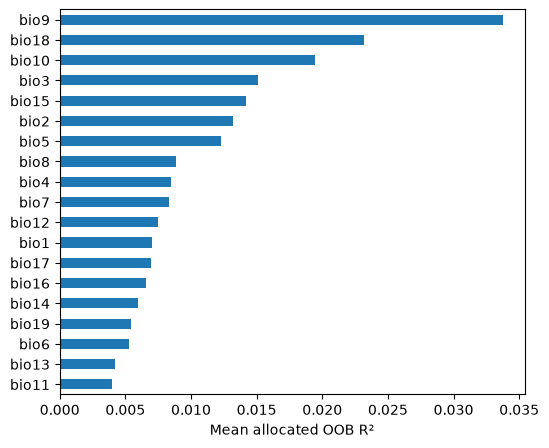

In [30]:
# Make a labeled horizontal bar plot of gf.importance_.
gf.importance_.sort_values().plot.barh(figsize=(6, 5), xlabel="Mean allocated OOB R²");
# Display the three highest-ranked predictors and their importance values.
top_three_bioclim= gf.importance_.sort_values(ascending=False).head(3)
top_three_bioclim

**Interpretation:** Name your top three climate variables. Suggest a biological explanation for one association, and one reason that predictor importance does not isolate a causal effect. How could correlation among the 19 climate predictors complicate the ranking?

My top 3 are Mean temp of driest quarter, precip of warmest quater, and mean temp of warmest quarter. A biological explantion of one association could be that rattlesnakes prefer warm, dry climates, so predictors that involve warm adn dry quaters could have a greater influence. Predicor importance does not isolate a causal effect becasue correlation does not imply causation. The ranking could becoem complciated becasue soem predicotrs are direclty related to others, such as mean annual temp and any of the temperatrue predictors. 
*Your answer:*

## 8. Plot cumulative turnover curves

Run the lab's plotting recipe below to show the six leading predictors. Each x axis uses that predictor's environmental values; check the raster units or scaling before assigning physical units. Each endpoint equals the predictor's importance.


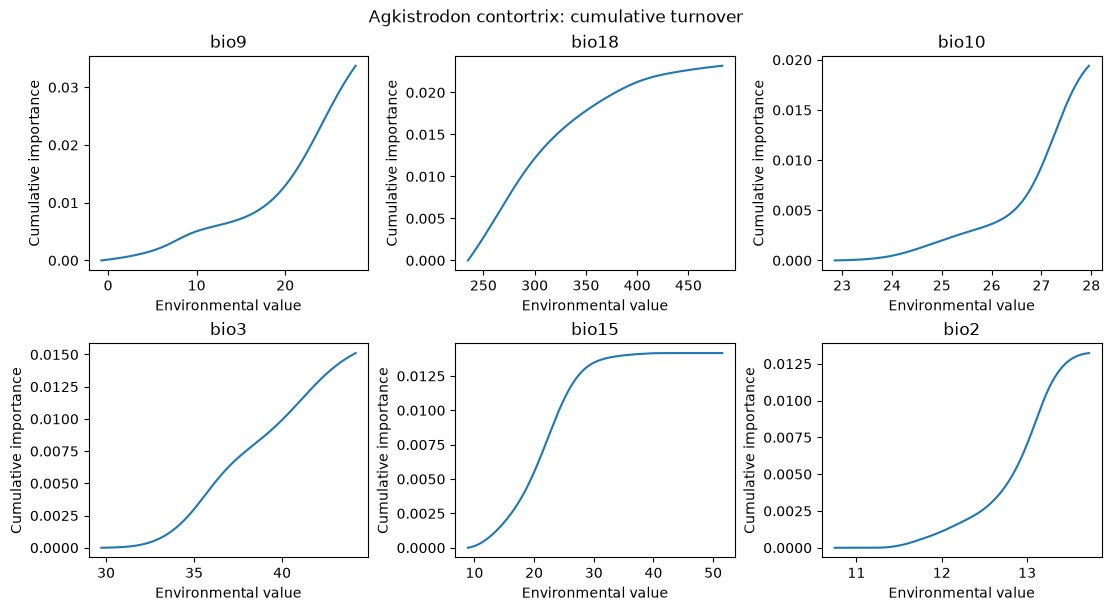

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
for ax, name in zip(axes.flat, gf.importance_.head(6).index):
    curve = gf.turnover_[name]
    ax.plot(curve.value, curve.cumulative_importance)
    ax.set(title=name, xlabel="Environmental value", ylabel="Cumulative importance")
fig.suptitle(f"{species_name}: cumulative turnover")
plt.show()
curves_figure = fig


**Interpretation:** Choose one curve and describe the environmental interval where it rises most rapidly, using approximate x-axis values. What does a high but flat section mean? Why can the cumulative curve increase even when some SNP dosages decrease along the gradient?

*Your answer:*
    For bio15, there is a steep rise in turnover between 20 and 30. The high but flat section is the endpoint value, or total predicotr importance. The curves measure magnitude, not direction (not pos or neg) so the curve can increase even if SNP dosgae decreases. 

## 9. Transform sampled environments and map a turnover layer

Use `gf.transform(X)` to create `turnover`, then display its first rows and dimensions. This returns one turnover coordinate per environmental predictor for each individual. In pyGF, `predict()` aliases `transform()`; it does not return predicted allele frequencies.

The map call below uses the leading predictor and the same regional bioclim directory. It samples every fourth raster cell in a region buffered 20% around the sites, as in the lab. Missing predictor pixels are masked; values beyond a fitted predictor range are clamped to its curve endpoint.


In [36]:
# Create turnover with gf.transform(X).
turnover = gf.transform(X)
# Display turnover.head() and turnover.shape.
turnover.head()

,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
CAS203553,0.000000,0.000026,0.000000,0.008411,0.000103,0.000227,0.007896,0.006996,0.000040,0.000197,0.000017,0.000300,0.000000,0.000392,0.008077,0.000000,0.000172,0.007117,0.000123
CAS203555,0.000089,0.004271,0.001366,0.007808,0.000222,0.000442,0.007682,0.002501,0.000278,0.000133,0.000147,0.001338,0.000566,0.000961,0.005124,0.000728,0.000708,0.008299,0.000375
CAS203566,0.002393,0.001185,0.001742,0.006302,0.002488,0.002630,0.005416,0.004239,0.028739,0.003471,0.001230,0.004860,0.001649,0.004020,0.005070,0.003968,0.003950,0.005909,0.002374
CAS203564,0.000431,0.006295,0.001377,0.007836,0.001293,0.000691,0.007954,0.003020,0.000508,0.001131,0.000319,0.003103,0.001127,0.002645,0.003121,0.002186,0.003534,0.009436,0.001445
KU337018,0.000070,0.005445,0.000085,0.008514,0.001733,0.000000,0.008345,0.007406,0.000000,0.001827,0.000000,0.000000,0.001649,0.000000,0.014166,0.002900,0.000000,0.015059,0.000000


In [37]:
turnover.shape

(32, 19)

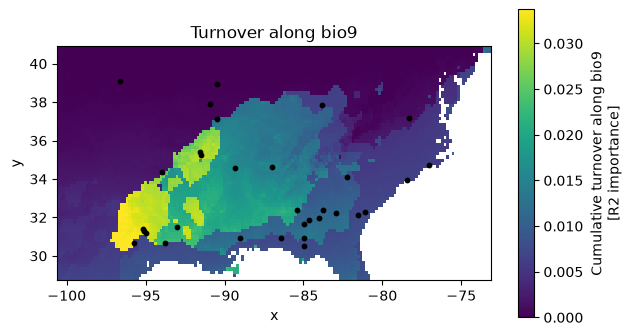

In [38]:
turnover_map = gf.plot_turnover(environment=bioclim_dir, points=sites)


**Interpretation:** Which predictor is mapped? Describe one geographic transition in its transformed values. Why is a high map value not necessarily a place with rapid local turnover? What happens outside the predictor's training range, and why does this limit interpretation?

*Your answer:*
Bio9 is mapped (mean temp of driest quarter). One geograghic transformation is from north to south where the cummulative turnover increases. High map value is not necessarily a place with rapid local turnover because the value is cummualitve, and therefore not neccesarily about to be compared well to points near it. Outside the predictors traning range, they get the same value as teh edge of the raneg becasue there is not data for that area. 
## 10. Make an aggregate spatial PCA biplot

Create `biplot` with `gf.plot_biplot(X, sites, environment=bioclim_dir, n_vectors=3)`. The map and ordination share colors from the first three PCs of the GF-transformed environments. PC1 and PC2 locate points in the biplot; PC1/2/3 supply the color channels.

The PCA uses transformed raster environments without standardizing columns to unit variance, preserving GF importance weights. Labelled arrows are environmental covariance loadings: direction indicates increasing transformed environmental values, and relative length indicates contribution to the displayed PC1/2 pattern.


,PC1,PC2,PC3,length,importance
bio9,0.007395,-0.001870,0.003304,0.007628,0.033734
bio18,0.002927,0.005317,-0.003001,0.006069,0.023177
bio10,0.001811,-0.004245,-0.001499,0.004615,0.019412
bio5,-0.000039,-0.003882,-0.000446,0.003883,0.012284
bio15,-0.002146,-0.002940,-0.001995,0.003640,0.014166
bio3,0.003310,-0.001173,-0.002425,0.003512,0.015111
bio2,-0.000015,-0.002301,-0.001246,0.002301,0.013224
bio12,0.002075,0.000959,-0.000233,0.002285,0.007512
bio7,-0.002191,-0.000174,0.001081,0.002198,0.008345
bio4,-0.002148,0.000291,0.001388,0.002168,0.008514


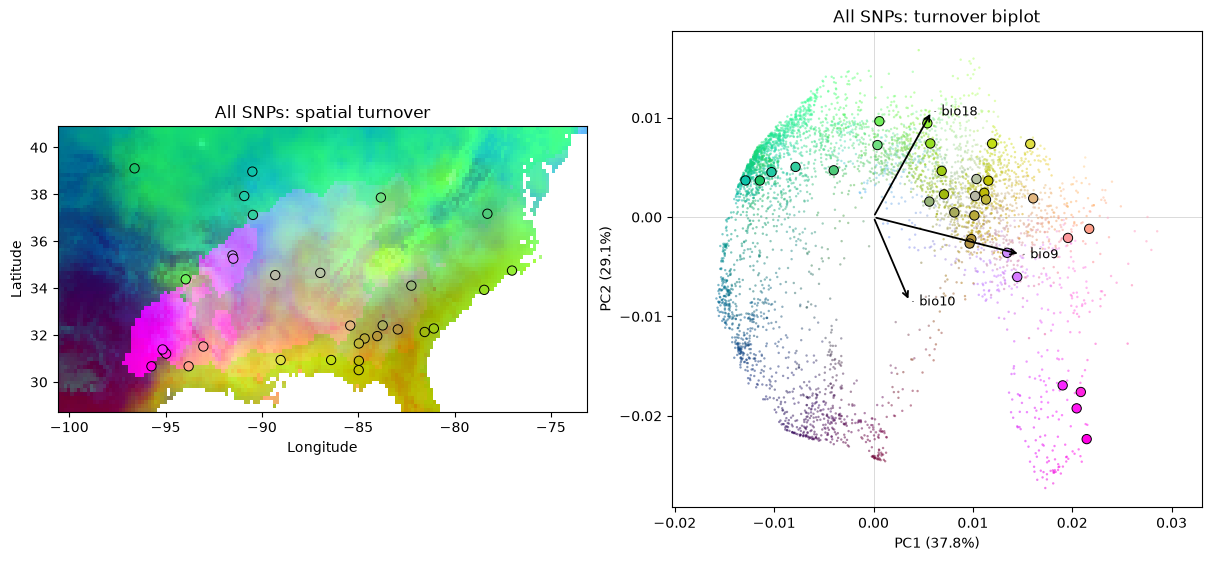

In [41]:
# Create biplot with the call above.
biplot = gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", n_vectors=3)
# Display biplot.vectors to inspect the environmental arrows.
biplot.vectors

**Interpretation:** Describe the main geographic color transition and an environmental arrow associated with it. What does similarity in color summarize? Why do neither the colors nor the arrows measure fitness or prove local adaptation? The arrow points towards the pink color

*Your answer:*
Bioclim09, yellow to pink transition. The arrow points towards the pink color and is the longest of the three, indicating that this predictor accounts for a large amount of the pattern shown. Color shows association not fitness so we cannot make meanigful conclusions about fitness or local adapation. 
## 11. Compare with a single-SNP biplot

Select the highest-OOB-R² SNP among contributing responses using the provided code. Create `snp_biplot` with the same call as before, adding `response=snp`. Use **`environment=bioclim_dir` in both biplot calls**, rather than an upstream-relative `../envs` path.

Each response has its own PCA basis and color calibration. Compare geographic organization and arrows; matching colors across separate plots have no shared genetic meaning. Selecting the best-scoring SNP is an illustration, not independent validation or discovery of an adaptive locus.


Selected SNP: RAD_22554:27:G:A
n_observed            26
oob_r2          0.577372
oob_coverage         1.0
retained            True
reason          retained
Name: RAD_22554:27:G:A, dtype: object


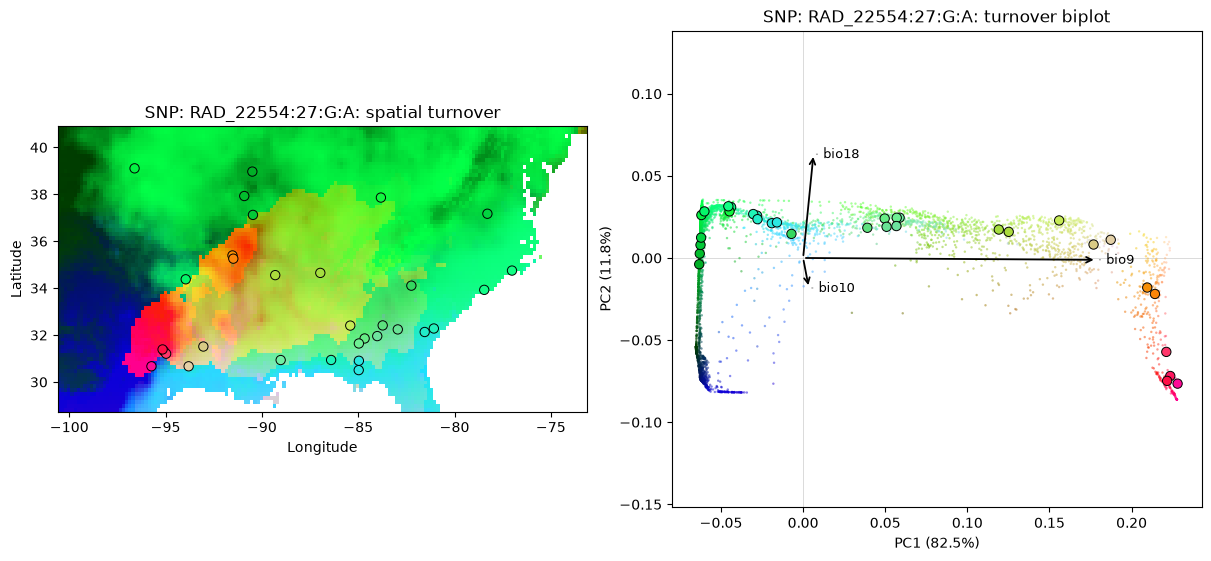

In [42]:
contributing_scores = gf.response_scores_.loc[gf.response_scores_["retained"]]
snp = contributing_scores["oob_r2"].idxmax()
print("Selected SNP:", snp)
print(contributing_scores.loc[snp])

# Create snp_biplot using gf.plot_biplot(), environment=bioclim_dir,
snp_biplot= gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", n_vectors=3, response=snp)
# response=snp, and n_vectors=3.


**Interpretation:** How does this SNP's geographic pattern differ from the aggregate pattern? Can you interpret a red region in both plots as the same genetic composition? Explain.

*Your answer:*
Both maps look similar, except the single-snp plot shows a larger transition for bioclim9. Also, the arrow for bioclim9 is now on the x axis for this plot. The single SNP plot is only one response, so you can somewhat interpret the red region as the same genetic composition, however the aggregate plot is a better summery of the geentic composition in the area. 
## 12. Export your results

The export recipe below follows the lab. It saves outputs under `Assignment09_outputs/<your file stem>/`, keeping runs for different species separate. The GeoTIFF contains one named band per environmental predictor, not per SNP.

Run the cell after completing the earlier steps. Keep the sample IDs in exported tables and preserve the raster's CRS and NoData mask. The small summary records the species, data paths, filtering choices, and model settings used in this analysis.


In [44]:
gf.response_scores_.to_csv(output_dir / "snp_oob_scores.csv")
gf.importance_.to_csv(output_dir / "predictor_importance.csv")
turnover.to_csv(output_dir / "sample_turnover.csv")
sites[["longitude", "latitude"]].to_csv(output_dir / "sample_coordinates.csv")
pd.concat(gf.turnover_, names=["predictor", "bin"]).to_csv(output_dir / "turnover_curves.csv")

summary = pd.DataFrame([{
    "species": species_name,
    "file_stem": target_species,
    "vcf": str(vcf_path),
    "coordinates": str(coords_path),
    "bioclim_directory": str(bioclim_dir),
    "n_individuals": len(X),
    "n_predictors": X.shape[1],
    "n_snps": y.shape[1],
    "n_contributing": int(gf.response_scores_["retained"].sum()),
    "min_call_rate": 0.8,
    "min_maf": 0.05,
    "one_per_contig": True,
    "max_variants": 256,
    "n_estimators": 100,
    "max_level": 2,
    "random_state": 42,
}])
summary.to_csv(output_dir / "analysis_summary.csv", index=False)

bands = turnover_map.turnover.to_array("band").rio.write_nodata(np.nan)
bands.attrs["long_name"] = tuple(X.columns)
bands.rio.to_raster(output_dir / "genomic_turnover.tif", compress="deflate", dtype="float32")

curves_figure.savefig(output_dir / "turnover_curves.png", dpi=150, bbox_inches="tight")
turnover_map.figure.savefig(output_dir / "turnover_map.png", dpi=150, bbox_inches="tight")
biplot.figure.savefig(output_dir / "turnover_biplot.png", dpi=150, bbox_inches="tight")
snp_biplot.figure.savefig(output_dir / "snp_biplot.png", dpi=150, bbox_inches="tight")

print("Saved results to:", output_dir.resolve())
summary


Saved results to: /home/jovyan/BIO597-SpatialBiodiversity/docs/assignments/Assignment09_outputs/Acontortrix


,species,file_stem,vcf,coordinates,bioclim_directory,n_individuals,n_predictors,n_snps,n_contributing,min_call_rate,min_maf,one_per_contig,max_variants,n_estimators,max_level,random_state
0,Agkistrodon contortrix,Acontortrix,/home/jovyan/shared/EasternSnakeGenetics/Acont...,/home/jovyan/shared/EasternSnakeGenetics/Acont...,/home/jovyan/shared/bioclim,32,19,256,86,0.8,0.05,True,256,100,2,42


## Final reflection

Answer each question in two or three sentences, referring to your figures or diagnostic results.

1. How does this genotype-based analysis differ from the species presence/background SDMs in Labs07–08? Why is a turnover coordinate different from a suitability score or allele frequency?
This analysis differes becasue we are comparing diversity within a species to climte predictors rather than species abundance. Turnover coordinate is different from suitibility score or allele frequency becasue turnover measures a position along the importance curve, rather than suitability is as an absolute metric. 

2. Which predictor and environmental interval showed a clear turnover pattern for your species? What evidence supports your description, and what sampling or modeling choice could change it?
Bioclim 9 basde on the importance metric as well as the PCA graphs. Differnt SNP filtering steps could change this output. 

3. Describe one alternative to local adaptation that could produce a genetic–environmental association. What additional data or analysis would help distinguish the explanations?
One alternative could be isolation by distance, which could produce the same results. I personally would perform an admixture analysis to confirm this. 

4. What would you withhold to test prediction in a new region? Explain why OOB evaluation alone does not answer that question.
I would withhold testing in a specific region, the way it is now the model would be trained on teh region I am tryign to test it on. This is the same reason OOB evaluation alone does not answer the question, becasue 
*Your answers:*

## Submit your work

Restart the kernel and run the notebook from top to bottom after completing the code prompts. Check that your figures appear, written answers are filled in, diagnostic counts are reported, and all exports exist. Commit and push this notebook and your species' output folder to your class GitHub repository. The original VCF and climate rasters remain in shared storage and should not be included in your submission.

Run these Git commands **from the repository root**, replacing `YOUR_SPECIES` with your chosen file stem:

```bash
git add docs/assignments/Assignment-09-GradientForest.ipynb docs/assignments/Assignment09_outputs/YOUR_SPECIES/
git commit -m "Complete Gradient Forest assignment"
git push
```

## References

- [Lab09: Gradient Forest](../labs/Lab09-GradientForest.ipynb)
- [Lecture09: Gradient Forest and Genomic Turnover](../lectures/Lecture09-GradientForest.html)
- [pyGF implementation and interpretation notes](https://github.com/isaacovercast/pygf)
- [Ellis, Smith & Pitcher (2012): the original Gradient Forest method](https://doi.org/10.1890/11-0252.1)
- [WorldClim bioclimatic variable definitions](https://www.worldclim.org/data/bioclim.html)
